<p style="
background: linear-gradient(135deg, #4caf50, #1a237e);
font-family:Trebuchet MS;
color:white;
font-size:190%;
text-align:center;
padding:15px;
border-radius:25px;
font-weight:bold;
box-shadow:0px 4px 15px rgba(0,0,0,0.4);">
Financial Fraud Detection in Digital Transactions
</p>

<p style="
font-family:Trebuchet MS;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-bottom:3px solid #64B5F6;
padding-bottom:5px;">
Problem Statement
</p>

<p style="
font-family:Calibri;
font-size:115%;
line-height:1.6;">
This project aims to detect fraudulent mobile transactions using machine learning models.
Our goal is to build a predictive model that flags suspicious transactions, with a focus on catching all potential frauds to minimize financial losses, making recall for the fraudulent class our key priority.
</p>


<p style="
font-family:Trebuchet MS;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-bottom:3px solid #64B5F6;
padding-bottom:5px;">
Objectives
</p>

<ul style="
font-family:Calibri;
font-size:115%;
line-height:1.6;
padding-left:15px;">
  <li><b>Dataset Exploration:</b> Analyze transaction types, amounts, and balance variations to identify patterns associated with fraudulent behavior.</li>
  <li><b>EDA & Insights:</b> Perform exploratory analysis to uncover key fraud indicators such as abnormal balance changes and high-risk transaction sequences.</li>
  <li><b>Data Preparation:</b> Prepare and preprocess the dataset by handling missing values, treating outliers, encoding categorical variables and transforming skewed features for model stability.</li>
  <li><b>Model Development:</b> Build and optimize ML Models (Logistic Regression, Random Forest, XGBoost) while addressing class imbalance to ensure accurate fraud detection.</li>
  <li><b>Evaluation & Impact:</b> Assess model performance using precision, recall, F1-score, and ROC-AUC metrics, balancing fraud detection effectiveness with false positive control.</li>
</ul>

<p style="
font-family:Verdana;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-left:5px solid #f44336;
padding-left:10px;">
STEP -1 | IMPORT LIBRARIES
</p>

In [119]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score
import time

import warnings
warnings.filterwarnings('ignore')

<p style="
font-family:Verdana;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-left:5px solid #f44336;
padding-left:10px;">
STEP - 2 | LOAD DATASET
</p>

In [120]:
fraud_data = pd.read_csv("Fraud_Analysis_Dataset.csv")

In [121]:
fraud_data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,C1305486145,181.0,0.0,C553264065,0.0,0.0,1
1,1,CASH_OUT,181.0,C840083671,181.0,0.0,C38997010,21182.0,0.0,1
2,1,TRANSFER,2806.0,C1420196421,2806.0,0.0,C972765878,0.0,0.0,1
3,1,CASH_OUT,2806.0,C2101527076,2806.0,0.0,C1007251739,26202.0,0.0,1
4,1,TRANSFER,20128.0,C137533655,20128.0,0.0,C1848415041,0.0,0.0,1


<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 2.1 Dataset Basic Information
</p>

In [122]:
fraud_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11142 entries, 0 to 11141
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            11142 non-null  int64  
 1   type            11142 non-null  object 
 2   amount          11142 non-null  float64
 3   nameOrig        11142 non-null  object 
 4   oldbalanceOrg   11142 non-null  float64
 5   newbalanceOrig  11142 non-null  float64
 6   nameDest        11142 non-null  object 
 7   oldbalanceDest  11142 non-null  float64
 8   newbalanceDest  11142 non-null  float64
 9   isFraud         11142 non-null  int64  
dtypes: float64(5), int64(2), object(3)
memory usage: 870.6+ KB


##### Checking for null values

In [123]:
fraud_data.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64

In [124]:
fraud_data.shape

(11142, 10)

In [125]:
fraud_data.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud'],
      dtype='object')

<p style="
font-family:Trebuchet MS;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-bottom:3px solid #64B5F6;
padding-bottom:5px;">
Inferences
</p>

<ul style="
font-family:Calibri;
font-size:115%;
line-height:1.6;
padding-left:15px;">
  <li><b>Total Entries:</b> The dataset contains 11,142 rows, where each row represents a single financial transaction.</li>
  <li><b>Columns:</b> There are 10 columns capturing transaction timing, type, amount, sender and receiver account details, balance information, and the fraud indicator.</li>
  <li><b>Data Types:</b>
    <ul>
      <li>Numerical features include <i>step</i>, <i>amount</i>, balance-related columns, and the target variable <i>isFraud</i>.</li>
      <li>Categorical features include <i>type</i>, <i>nameOrig</i>, and <i>nameDest</i>, representing transaction type and account identifiers.</li>
    </ul>
  </li>
  <li><b>Missing Values:</b> There are no null values in the dataset, so no imputation is required.</li>
</ul>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 2.2 Summary Statistics
</p>

##### Numerical Attributes - Summary Statistics

In [126]:
fraud_data.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
count,11142.000000,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,1.114200e+04,11142.000000
mean,8.717645,2.131915e+05,9.241173e+05,8.249576e+05,8.883541e+05,1.103211e+06,0.102495
std,16.067479,7.600650e+05,2.143004e+06,2.089894e+06,2.601376e+06,2.982447e+06,0.303312
min,1.000000,2.390000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2.000000,4.946618e+03,4.270000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
50%,6.000000,1.676126e+04,2.816950e+04,4.420605e+03,0.000000e+00,0.000000e+00,0.000000
75%,7.000000,1.543366e+05,3.040855e+05,1.114126e+05,2.711555e+05,3.186374e+05,0.000000
max,95.000000,1.000000e+07,1.990000e+07,1.300000e+07,3.300000e+07,3.460000e+07,1.000000


##### Fraud Distribution

In [127]:
fraud_data['isFraud'].value_counts()

isFraud
0    10000
1     1142
Name: count, dtype: int64

##### Categorical Attributes - Summary Statistics

In [128]:
fraud_data.describe(include='object')

,type,nameOrig,nameDest
count,11142,11142,11142
unique,5,11142,7508
top,PAYMENT,C1305486145,C985934102
freq,5510,1,62


<p style="
font-family:Trebuchet MS;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-bottom:3px solid #64B5F6;
padding-bottom:5px;">
Inferences
</p>

<ul style="
font-family:Calibri;
font-size:115%;
line-height:1.6;
padding-left:15px;">
  <li><b>Fraud Distribution:</b> About 10% of transactions are fraudulent, showing class imbalance.</li>
  <li><b>Most frequent:</b> "Payment" - with 5510 occurrences → This is the dominant transaction type, accounting for nearly half the dataset.</li>
  <li><b>nameOrig:</b> 11,142 unique sender accounts; each appears only once.</li>
  <li><b>nameDest:</b> 7,508 unique receiver accounts; some reused frequently (top one appears 62 times).</li> 
</ul>

<p style="
font-family:Verdana;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-left:5px solid #f44336;
padding-left:10px;">
STEP - 3 | EXPLORATORY DATA ANALYSIS | EDA
</p>

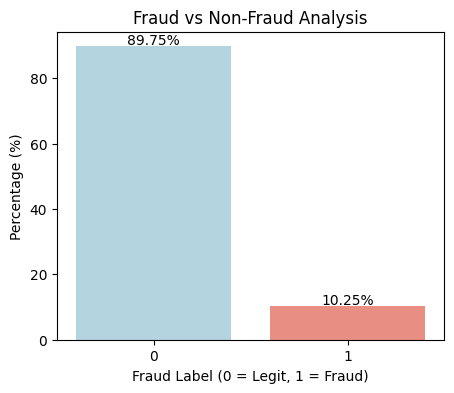

In [129]:
#Calculate Fraud %
fraud_rate = fraud_data["isFraud"].value_counts(normalize= True) * 100 

#Bar Chart
plt.figure(figsize=(5,4))
ax = sns.barplot(x=fraud_rate.index,y=fraud_rate.values, palette=['lightblue','salmon'])

plt.title("Fraud vs Non-Fraud Analysis")
plt.xlabel("Fraud Label (0 = Legit, 1 = Fraud)")
plt.ylabel("Percentage (%)")

#Add exact % on bars
for i,value in enumerate(fraud_rate):
    ax.text(i,value + 0.5,f"{value:.2f}%",ha='center',fontsize=10)
    
plt.show()

<p style="
font-family:Trebuchet MS;
font-size:120%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
<b>Inference:</b><br>
The dataset reveals a significant class imbalance. Out of 11,142 transactions, 
10,000 (≈89.75%) are legitimate while 1,142 (≈10.25%) are fraudulent. 
Although fraud cases form a minority, their impact is critical.
This imbalance highlights the importance of prioritizing <b>recall</b> and <b>precision</b> 
over overall accuracy, since missing fraudulent transactions can lead to direct financial losses.
</p>

In [130]:
# Calculate fraud rate by transaction type
transaction_type_fraud_rate = (
    fraud_data.groupby("type")
      .agg(
          total_transactions=("isFraud", "count"),
          fraud_transactions=("isFraud", "sum")
      )
)

# Fraud rate percentage
transaction_type_fraud_rate["fraud_rate_pct"] = (
    transaction_type_fraud_rate["fraud_transactions"] /
    transaction_type_fraud_rate["total_transactions"] * 100
)

# Sort by fraud rate 
transaction_type_fraud_rate = transaction_type_fraud_rate.sort_values(
    by ="fraud_rate_pct",ascending=False
)
transaction_type_fraud_rate


,total_transactions,fraud_transactions,fraud_rate_pct
type,,,
TRANSFER,1464,564,38.524590
CASH_OUT,1871,578,30.892571
CASH_IN,1951,0,0.000000
DEBIT,346,0,0.000000
PAYMENT,5510,0,0.000000


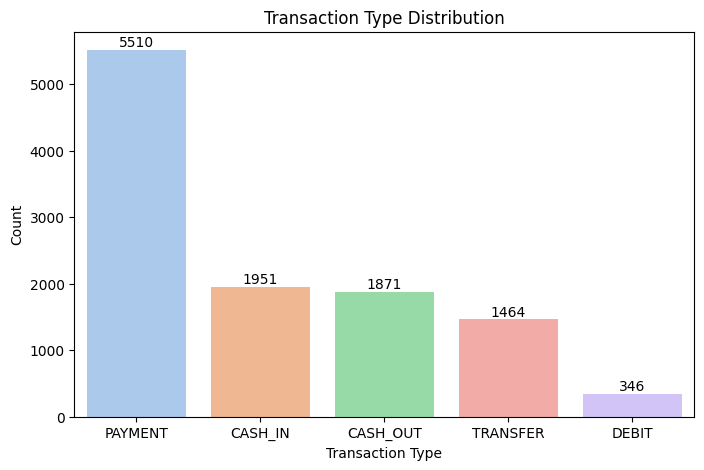

In [131]:
# Calculate transactin counts by type
transaction_counts = fraud_data["type"].value_counts()

#Barplot
plt.figure(figsize=(8,5))
ax = sns.barplot(x=transaction_counts.index,y=transaction_counts.values,palette="pastel")

# Add counts on top of bars
for i,count in enumerate(transaction_counts.values):
    ax.text(i, count + 50,str(count),ha='center',fontsize=10)

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
• This bar shows the frequency of each transaction type in the dataset, revealing which types are most and least common<br>
• This provides insight into the overall distribution of transaction activities.<br>
</p>

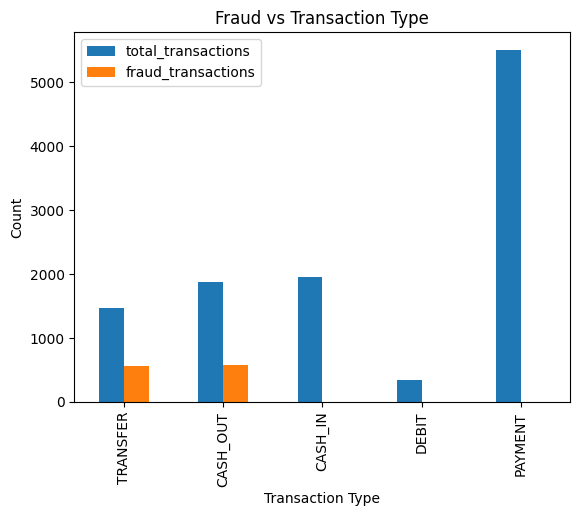

In [132]:
# Compare total transactions and fraudulent transactions across transaction types
transaction_type_fraud_rate[
    ["total_transactions", "fraud_transactions"]
].plot(
    kind="bar",
)

plt.title("Fraud vs Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.legend()
plt.show()

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
<b>Inference:</b><br>
• Fraud is concentrated in <b>TRANSFER</b> and <b>CASH_OUT</b> transactions.<br>
<b>• CASH_IN, DEBIT, and PAYMENT</b> have negligible or zero fraud.<br>
• Fraud follows a structured pattern (Transfer → Cash Out).<br> 
<b>• Transaction type is a strong predictive feature for fraud detection<br>
</p>

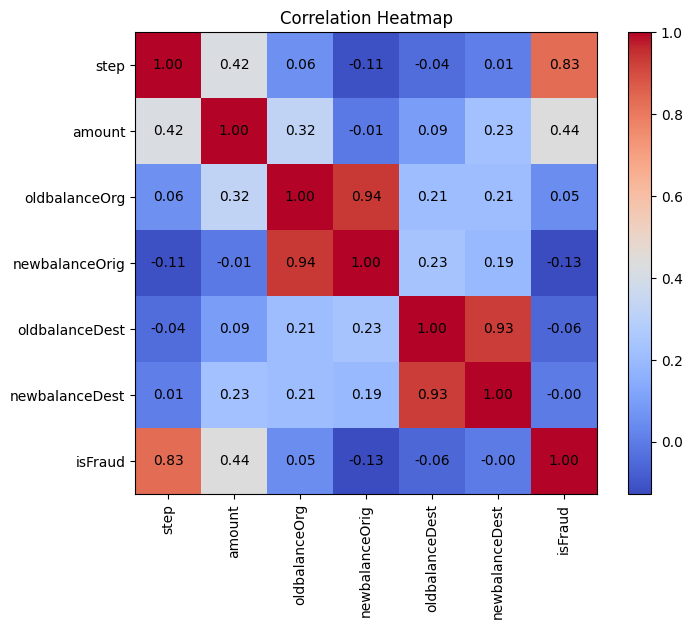

In [133]:
# Analyze correlations between numerical features using a heatmap
plt.figure(figsize=(8,6))
corr = fraud_data.select_dtypes(include='number').corr()
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

# Add data labels
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.title("Correlation Heatmap")
plt.grid(False)
plt.show()


<h3 style="
font-family:Trebuchet MS;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-bottom:3px solid #64B5F6;
padding-bottom:5px;">
Key Findings
</h3>

<table style="
font-family:Trebuchet MS;
width:100%;
border-collapse:collapse;
font-size:95%;
color:#334155;
background-color:#ffffff;">

<thead>
<tr style="background-color:#e8eaf6;color:#1a237e;">
<th style="padding:12px;text-align:left;border:1px solid #dbe1ea;">Variable Pair</th>
<th style="padding:12px;text-align:center;border:1px solid #dbe1ea;">Correlation</th>
<th style="padding:12px;text-align:left;border:1px solid #dbe1ea;">Initial Interpretation</th>
</tr>
</thead>

<tbody>
<tr style="background-color:#ffffff;">
<td style="padding:10px;border:1px solid #e2e8f0;"><code>oldbalanceOrg</code> and <code>newbalanceOrig</code></td>
<td style="padding:10px;text-align:center;border:1px solid #e2e8f0;color:#15803d;"><b>0.94</b></td>
<td style="padding:10px;border:1px solid #e2e8f0;">Strong positive relationship</td>
</tr>

<tr style="background-color:#f8fafc;">
<td style="padding:10px;border:1px solid #e2e8f0;"><code>oldbalanceDest</code> and <code>newbalanceDest</code></td>
<td style="padding:10px;text-align:center;border:1px solid #e2e8f0;color:#15803d;"><b>0.93</b></td>
<td style="padding:10px;border:1px solid #e2e8f0;">Strong positive relationship</td>
</tr>

<tr style="background-color:#ffffff;">
<td style="padding:10px;border:1px solid #e2e8f0;"><code>step</code> and <code>isFraud</code></td>
<td style="padding:10px;text-align:center;border:1px solid #e2e8f0;color:#dc2626;"><b>0.83</b></td>
<td style="padding:10px;border:1px solid #e2e8f0;">Unusually strong positive relationship</td>
</tr>

<tr style="background-color:#f8fafc;">
<td style="padding:10px;border:1px solid #e2e8f0;"><code>amount</code> and <code>isFraud</code></td>
<td style="padding:10px;text-align:center;border:1px solid #e2e8f0;color:#b77900;"><b>0.44</b></td>
<td style="padding:10px;border:1px solid #e2e8f0;">Moderate positive relationship</td>
</tr>

<tr style="background-color:#ffffff;">
<td style="padding:10px;border:1px solid #e2e8f0;"><code>newbalanceOrig</code> and <code>isFraud</code></td>
<td style="padding:10px;text-align:center;border:1px solid #e2e8f0;color:#2563eb;"><b>-0.13</b></td>
<td style="padding:10px;border:1px solid #e2e8f0;">Weak negative linear relationship</td>
</tr>

<tr style="background-color:#f8fafc;">
<td style="padding:10px;border:1px solid #e2e8f0;"><code>oldbalanceOrg</code> and <code>isFraud</code></td>
<td style="padding:10px;text-align:center;border:1px solid #e2e8f0;color:#64748b;"><b>0.05</b></td>
<td style="padding:10px;border:1px solid #e2e8f0;">Very weak linear relationship</td>
</tr>
</tbody>
</table>


<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Analysis of step and isFraud 
</p>

In [134]:
step_analysis = fraud_data.groupby('step').agg(
    total_transactions=('isFraud', 'count'),
    fraud_transactions=('isFraud', 'sum')
)

step_analysis['fraud_rate'] = (
    step_analysis['fraud_transactions'] /
    step_analysis['total_transactions'] * 100
).round(2)

step_analysis.sort_values(
    'fraud_rate',
    ascending=False
).head(20)

,total_transactions,fraud_transactions,fraud_rate
step,,,
14,12,12,100.0
13,14,14,100.0
12,14,14,100.0
11,7,7,100.0
10,11,11,100.0
9,19,19,100.0
8,12,12,100.0
15,20,20,100.0
22,23,23,100.0



<h3 style="
font-family:Trebuchet MS;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-bottom:3px solid #64B5F6;
padding-bottom:5px;">
Inference
</h3>



<ul style="
font-family:Calibri;
font-size:105%;
line-height:1.6;
padding-left:15px;">

<li><b>Class Imbalance:</b> The dataset contains 10,000 legitimate transactions (89.75%) and 1,142 fraudulent transactions (10.25%). This imbalance makes precision, recall, and F1-score important evaluation metrics.</li>

<li><b>Transaction Type:</b> Fraud is observed only in TRANSFER and CASH_OUT transactions in this dataset. TRANSFER has a fraud rate of 38.52%, while CASH_OUT has a fraud rate of 30.89%. Transaction type is a useful feature to investigate for fraud detection.</li>

<li><b>Sender Balance:</b> The sender's balance fell to zero in 97.46% of fraudulent transactions, compared with 16.03% of legitimate transactions. Sender balance depletion is strongly associated with fraud in this dataset.</li>

<li><b>Receiver Balance:</b> The mean receiver balance change is higher for fraudulent transactions (625,074.35) than for legitimate transactions (168,010.62). Receiver balance increases are also more frequent in fraudulent transactions.</li>

<li><b>Transaction Amount:</b> Fraudulent transactions have a higher mean amount (1,192,628.93) and median amount (353,179.45) than legitimate transactions, suggesting that transaction amount may be useful for distinguishing between the two groups.</li>

<li><b>Correlation Analysis:</b> Sender and receiver balances before and after transactions have strong positive correlations (0.94 and 0.93, respectively). The correlation between step and fraud is unusually high (0.83) and requires further investigation before using step as a predictive feature.</li>

<li><b>Key Finding:</b> Transaction type, sender balance depletion, receiver balance changes, and transaction amount show differences between fraudulent and legitimate transactions. These patterns will guide feature engineering and subsequent model development, but their predictive value must be validated during model evaluation.</li>

</ul>

<p style="
font-family:Verdana;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-left:5px solid #f44336;
padding-left:10px;">
STEP - 4 | DATA PREPROCESSING
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 4.1 Missing Value Treatment
</p>

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
<b>No Missing Values</b><br>
• The dataset is complete — every feature has valid entries.<br>
• No imputation or data cleaning is required for missing values.<br><br>
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 4.2 | Outliers Treatment
</p>

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
• High transaction amounts and large balance changes are valid fraud signals<br>
• Removing them reduces model ability to detect fraud.<br>
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 4.3 Irrelevant Features Removal
</p>

In [135]:
fraud_data = fraud_data.drop(['nameOrig', 'nameDest'], axis=1)
fraud_data.columns

Index(['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
       'oldbalanceDest', 'newbalanceDest', 'isFraud'],
      dtype='object')

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
<b>Inference:</b><br>
• nameOrig and nameDest are unique identifier fields with many distinct values, offering no predictive value.<br>
• Dropping these columns reduces noise and model complexity.<br>
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 4.4 | Feature Engineering
</p>

In [136]:
# Creating Balance - based features
# Captures abnormal balance behavior — key fraud indicator

In [137]:
fraud_data['balance_diff_orig'] = fraud_data['oldbalanceOrg'] - fraud_data['newbalanceOrig']
# Compares balance before and after the transaction ( Sender - Origin account)
# In normal transactions, the balance drop equals the transaction amount, 
# but fraud often breaks this rule — making balance difference a key fraud signal.

In [138]:
fraud_data['balance_diff_dest'] = fraud_data['newbalanceDest'] - fraud_data['oldbalanceDest']
# Compares balance after and before the transaction ( Receiver - destination account)
# Legitimate transactions match the amount, but fraud often shows mismatches or abnormal spikes

In [139]:
# 3. Balance consistency feature
fraud_data['amount_balance_mismatch'] = fraud_data['amount'] - fraud_data['balance_diff_orig']

# Legitimate transactions - the sender’s balance drop should equal the transaction amount.
# Fraudulent transactions - mismatches often appear - making this a strong fraud signal.

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 4.5 | Encoding categorical variables 
</p>

In [140]:
fraud_data = pd.get_dummies(fraud_data, columns=['type'], drop_first=True)

In [141]:
fraud_data.sample()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balance_diff_orig,balance_diff_dest,amount_balance_mismatch,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
10156,7,5680.34,0.0,0.0,0.0,0.0,0,0.0,0.0,5680.34,False,False,True,False


In [142]:
fraud_data.shape

(11142, 14)

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 4.6 | Splitting Features & Target 
</p>

In [143]:
# Separate features and target, excluding step
x = fraud_data.drop(columns=['isFraud','step'])
y = fraud_data['isFraud']

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 4.7 | Train–test split 
</p>

In [144]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
<b>Inference:</b><br>
• Converted transaction types into numbers using one‑hot encoding.<br>
• Separated features (X) from target (isFraud).<br>
• Did train–test split early to avoid data leakage.<br>
• Final dataset is clean, numeric, and ready for machine learning models.
</p>

<p style="
font-family:Verdana;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-left:5px solid #f44336;
padding-left:10px;">
STEP - 5 | MODEL BUILDING
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 5.1 | LOGISTIC REGRESSION MODEL 
</p>

In [145]:
# Select numeric columns from training data
num_cols = x_train.select_dtypes(include=['int64', 'float64']).columns

# Initialize StandardScaler for feature scaling
scaler = StandardScaler()

# Make copies of train and test sets to preserve original data
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

# Apply scaling to numeric columns (fit on train, transform on both)
x_train_scaled[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test_scaled[num_cols] = scaler.transform(x_test[num_cols])

In [146]:
lr_model = LogisticRegression(
    class_weight='balanced' # Helps the model perform better on imbalanced datasets.
)

# Train the model on scaled training data
lr_model.fit(x_train_scaled, y_train)

# Predict fraud labels on test data
y_pred_lr = lr_model.predict(x_test_scaled)

# Predict probabilities (IMPORTANT: use probability, not class)
y_pred_prob_lr = lr_model.predict_proba(x_test_scaled)[:, 1]

In [147]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Results")
print(f"Accuracy: {accuracy_lr:.2f}")
print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_prob_lr))

Logistic Regression Results
Accuracy: 0.94
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      3000
           1       0.61      0.98      0.76       343

    accuracy                           0.94      3343
   macro avg       0.81      0.96      0.86      3343
weighted avg       0.96      0.94      0.94      3343

ROC-AUC: 0.99


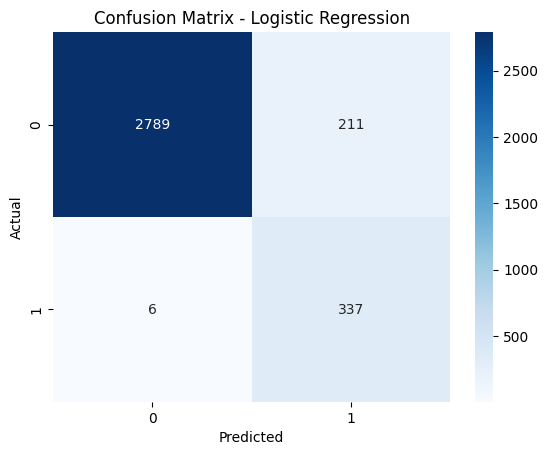

In [148]:
cm = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
<b>
Confusion Matrix – Logistic Regression:<br>
True Negatives: 2789 — correctly identified non‑fraud cases.<br>
True Positives: 337 — correctly detected fraud cases.<br>
False Positives: 211 — non‑fraud cases misclassified as fraud.<br>
False Negatives: 6 — fraud cases missed by the model.<br>
<b>Interpretation:</b><br>
Logistic Regression achieved 98.25% recall, detecting 337 out of 343 fraud cases. However, it generated 211 false positives, incorrectly flagging legitimate transactions as fraud.
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 5.2 | RANDOM FOREST MODEL 
</p>

In [149]:
# Initialize Random Forest model
rf_model = RandomForestClassifier(
)
# Train the model on training data
rf_model.fit(x_train, y_train)

# Predict fraud labels on test data
y_pred_rf = rf_model.predict(x_test)

y_pred_prob_rf = rf_model.predict_proba(x_test)[:, 1]

In [150]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Results")
print(f"Accuracy: {accuracy_rf:.2f}")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_prob_rf))

Random Forest Results
Accuracy: 1.00
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3000
           1       1.00      0.99      0.99       343

    accuracy                           1.00      3343
   macro avg       1.00      0.99      1.00      3343
weighted avg       1.00      1.00      1.00      3343

ROC-AUC: 0.9952142857142858


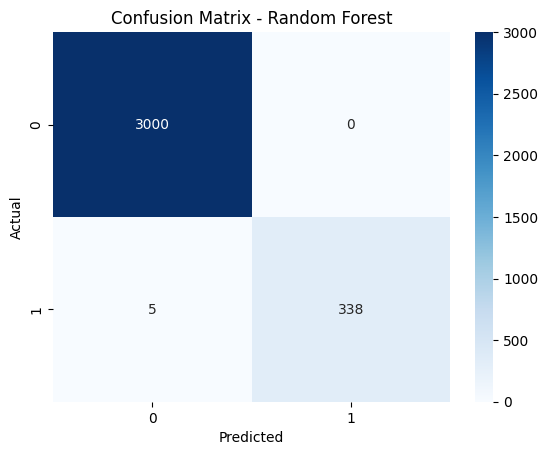

In [151]:
# Generate and display confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
Random Forest model:<br>
True Negatives: 3000 — all non‑fraud cases correctly classified.<br>
True Positives: 338 — successfully detected 338 fraudulent transactions.<br>
False Positives: 0 — no genuine transactions were wrongly flagged.<br>
False Negatives: 5 — failed to detect 5 fraudulent transactions.<br>
<b>Interpretation:</b><br>
Random Forest achieved 100% precision and 98.54% recall, correctly identifying all legitimate transactions and detecting 338 out of 343 fraud cases, with only 5 missed. It is a strong candidate for further validation.
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 5.3 | XGBoost Model 
</p>

In [152]:
xgb_model = XGBClassifier()

xgb_model.fit(x_train, y_train)

y_pred_xgb = xgb_model.predict(x_test)
y_pred_prob_xgb = xgb_model.predict_proba(x_test)[:, 1]

In [153]:
# Print evaluation results
accuracy_Xg = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Results")
print(f"Accuracy: {accuracy_Xg:.2f}")
print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_prob_xgb))

XGBoost Results
Accuracy: 1.00
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3000
           1       1.00      0.99      0.99       343

    accuracy                           1.00      3343
   macro avg       1.00      0.99      1.00      3343
weighted avg       1.00      1.00      1.00      3343

ROC-AUC: 0.9990889212827988


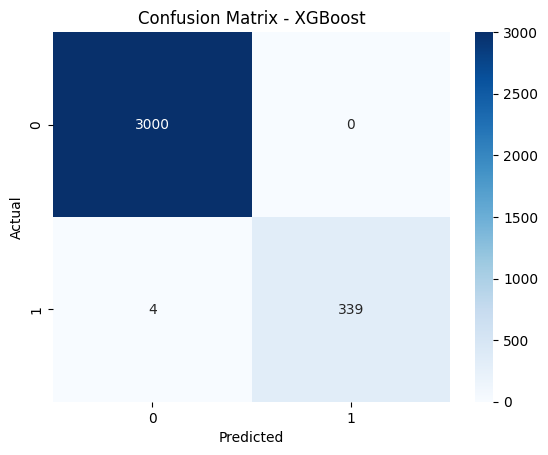

In [154]:
cm = confusion_matrix(y_test, y_pred_xgb)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBoost")
plt.show()

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
XGBoost demonstrated the strongest overall fraud detection performance, achieving 100% precision and 98.83% recall. It detected 339 out of 343 fraud cases with zero false positives, making it the strongest candidate for further validation.
</p>

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
<b>Conclusion:</b><br>
Among the three models tested:<br>
- Logistic Regression: Provided a baseline with high fraud recall but generated 211 false positives.<br>
- Random Forest: Achieved 100% precision and 98.54% recall, with only 5 misclassifications..<br>
- XGBoost: Achieved the best overall results, with 100% precision, 98.83% recall and only 4 misclassifications.<br>
<b>Inference:</b> Random Forest and XGBoost significantly outperformed Logistic Regression.
</p>

<p style="
font-family:Verdana;
font-size:140%;
font-weight:bold;
color:#4caf50;
border-left:5px solid #f44336;
padding-left:10px;">
STEP - 6 | DEPLOYMENT OF THE BEST MODEL
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 6.1 | Comparison of Best Models
</p>

In [155]:
comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'PR-AUC',
        'Training Time (seconds)',
        'Prediction Time (seconds)'
    ],

    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf),
        roc_auc_score(y_test, y_pred_prob_rf),
        pr_auc_rf,
        rf_train_time,
        rf_prediction_time
    ],

    'XGBoost': [
        accuracy_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_xgb),
        roc_auc_score(y_test, y_pred_prob_xgb),
        pr_auc_xgb,
        xgb_train_time,
        xgb_prediction_time
    ]
})

comparison = comparison.round(6)

comparison

,Metric,Random Forest,XGBoost
0,Accuracy,0.998504,0.998803
1,Precision,1.000000,1.000000
2,Recall,0.985423,0.988338
3,F1-Score,0.992658,0.994135
4,ROC-AUC,0.995214,0.999089
5,PR-AUC,0.999787,0.999773
6,Training Time (seconds),1.212255,0.590202
7,Prediction Time (seconds),0.036687,0.017281


<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
XGBoost was selected as the candidate final model due to its slightly better fraud detection performance and faster execution time
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 6.2 | Feature Importance
</p>

<Axes: title={'center': 'Top 10 Feature Importances - XGBoost'}>

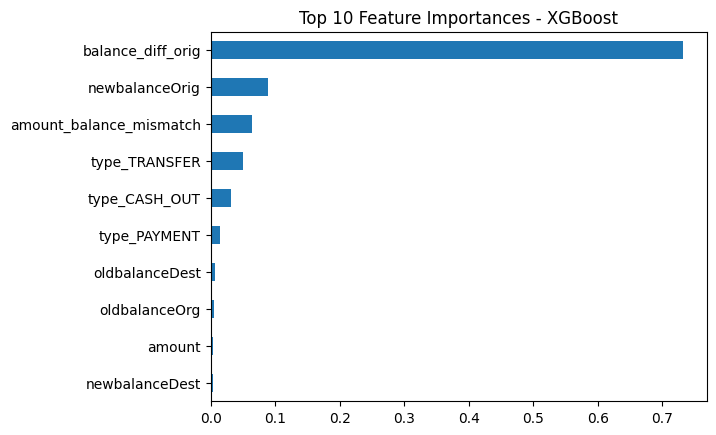

In [156]:
# importance of each feature in making predictions. 
importances_xgb = xgb_model.feature_importances_

weights_xgb = pd.Series(
    importances_xgb,
    index=x.columns
)

weights_xgb.sort_values().tail(10).plot(
    kind='barh',
    title='Top 10 Feature Importances - XGBoost'# features in ascending order of importance.
)

<p style="
font-family:Trebuchet MS;
font-size:115%;
font-weight:bold;
color:#1a237e;
border-left:5px solid #4caf50;
padding-left:10px;
background-color:#f1f8e9;">
</b>Inference :</b><br>
XGBoost identified `balance_diff_orig` as the most influential feature in fraud prediction, followed by `newbalanceOrig` and `amount_balance_mismatch`. Transaction types, particularly TRANSFER and CASH_OUT, also contributed to the predictions. This indicates that changes in account balances play an important role in identifying potentially fraudulent transactions.
</p>

<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 6.3 | Model Code 
</p>

In [159]:
import pandas as pd
import numpy as np
from joblib import dump

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier

# 1. Load dataset
df = pd.read_csv("Fraud_Analysis_Dataset.csv")

# 2. Feature Engineering
df['balance_diff_orig'] = (
    df['oldbalanceOrg'] - df['newbalanceOrig']
)

df['balance_diff_dest'] = (
    df['newbalanceDest'] - df['oldbalanceDest']
)

df['amount_balance_mismatch'] = (
    df['amount'] - df['balance_diff_orig']
)

# 3. Drop identifier columns and step
df.drop(
    ['nameOrig', 'nameDest', 'step'],
    axis=1,
    inplace=True
)

# 4. One-hot encode transaction type
df = pd.get_dummies(
    df,
    columns=['type'],
    drop_first=True
)

# 5. Separate features and target
x = df.drop('isFraud', axis=1)
y = df['isFraud']

# 6. Train-test split
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 7. Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# 8. Train model
xgb_model.fit(x_train, y_train)

# 9. Evaluate model
y_pred_xgb = xgb_model.predict(x_test)

print(classification_report(y_test, y_pred_xgb))
print(confusion_matrix(y_test, y_pred_xgb))

# 10. Save trained model and feature names
dump(xgb_model, 'fraud_detection_xgboost.joblib')
dump(x.columns.tolist(), 'model_features.joblib')

print("XGBoost model and feature list saved successfully.")

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3000
           1       1.00      0.99      0.99       343

    accuracy                           1.00      3343
   macro avg       1.00      0.99      1.00      3343
weighted avg       1.00      1.00      1.00      3343

[[3000    0]
 [   4  339]]
XGBoost model and feature list saved successfully.


<p style="
font-family:Verdana;
font-size:120%;
font-weight:bold;
color:#1b5e20;
border-left:5px solid #66bb6a;
padding-left:10px;">
Step 6.4 | App Code 
</p>

In [166]:
import streamlit as st
import pandas as pd
import joblib

# 1. Load trained XGBoost model and feature names
model = joblib.load("fraud_detection_xgboost.joblib")
features = joblib.load("model_features.joblib")

st.set_page_config(
    page_title="Fraud Detection App",
    layout="centered"
)

st.title("💳 - Mobile Transaction Fraud Detection - Naveen")
st.write("Enter transaction details to predict fraud risk.")

# 2. User inputs (step removed)
amount = st.number_input("Transaction Amount", min_value=0.0)
oldbalanceOrg = st.number_input("Old Balance (Sender)", min_value=0.0)
newbalanceOrig = st.number_input("New Balance (Sender)", min_value=0.0)
oldbalanceDest = st.number_input("Old Balance (Receiver)", min_value=0.0)
newbalanceDest = st.number_input("New Balance (Receiver)", min_value=0.0)

txn_type = st.selectbox(
    "Transaction Type",
    ["CASH-IN", "CASH-OUT", "DEBIT", "PAYMENT", "TRANSFER"]
)

# 3. Feature Engineering
balance_diff_orig = oldbalanceOrg - newbalanceOrig
balance_diff_dest = newbalanceDest - oldbalanceDest

amount_balance_mismatch = amount - balance_diff_orig

# 4. Create input dictionary
input_data = {
    'amount': amount,
    'oldbalanceOrg': oldbalanceOrg,
    'newbalanceOrig': newbalanceOrig,
    'oldbalanceDest': oldbalanceDest,
    'newbalanceDest': newbalanceDest,
    'balance_diff_orig': balance_diff_orig,
    'balance_diff_dest': balance_diff_dest,
    'amount_balance_mismatch': amount_balance_mismatch
}

# 5. One-hot encode transaction type
for col in [
    "type_CASH-OUT",
    "type_DEBIT",
    "type_PAYMENT",
    "type_TRANSFER"
]:
    input_data[col] = int(txn_type == col.replace("type_", ""))

# 6. Create DataFrame and align with training features
input_df = pd.DataFrame([input_data])
input_df = input_df.reindex(columns=features, fill_value=0)

# 7. Prediction
if st.button("Predict Fraud"):

    prob = model.predict_proba(input_df)[0][1]
    prediction = model.predict(input_df)[0]

    st.subheader("Prediction Result")
    st.write(f"Fraud Probability: **{prob:.2%}**")

    if prediction == 1:
        st.error("⚠️ Fraudulent Transaction Detected")
    else:
        st.success("✅ Legitimate Transaction")

2026-11-24 00:03:29.011 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-24 00:03:29.026 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-24 00:03:29.931 
  command:

    streamlit run C:\Users\JaRVis\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-24 00:03:29.931 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-24 00:03:29.931 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-24 00:03:29.947 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-24 00:03:29.947 Thread 'MainThread': missing ScriptRunContext! This w